# CatBoost Model Interpretation and Customer Risk Scores

This English notebook reuses the shared interpretation module for SHAP, LIME, and scorecards. It uses the supplied fitted model by default. The supplied model does not reproduce the separately supplied historical scorecard exactly, so the newly computed outputs stay separate from the original results. Full-sample diagnostics include training customers.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "project_paths.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from interpret_model import run
OUT = ROOT / "outputs" / "interpretation"

## Run the shared analysis

The model has 44 predictors and a high-risk threshold near 0.64. SHAP contributions use the raw model margin. LIME uses a fixed seed and regularized highest-weight feature selection. Install requirements-advanced.txt before running this notebook.

In [2]:
scorecard_path = run(seed=42, include_lime=True)

Interpreted CatBoost for 7043 customers; high-risk threshold: 0.64


## Global model contributions

Mean absolute SHAP ranks feature contributions across all customers. This ranking is recomputed from the supplied PKL and can differ from the original report table.

,feature,mean_abs_shap_value
0,is_two_year_contract,0.242258
1,uses_fiber_optic,0.232516
2,is_month_to_month,0.211844
3,tenure,0.209825
4,month_to_month_high_charge,0.180091
5,MonthlyCharges,0.149896
6,is_electronic_check,0.106289
7,PaperlessBilling_Yes,0.080845
8,TotalCharges,0.077312
9,add_on_service_count,0.075792


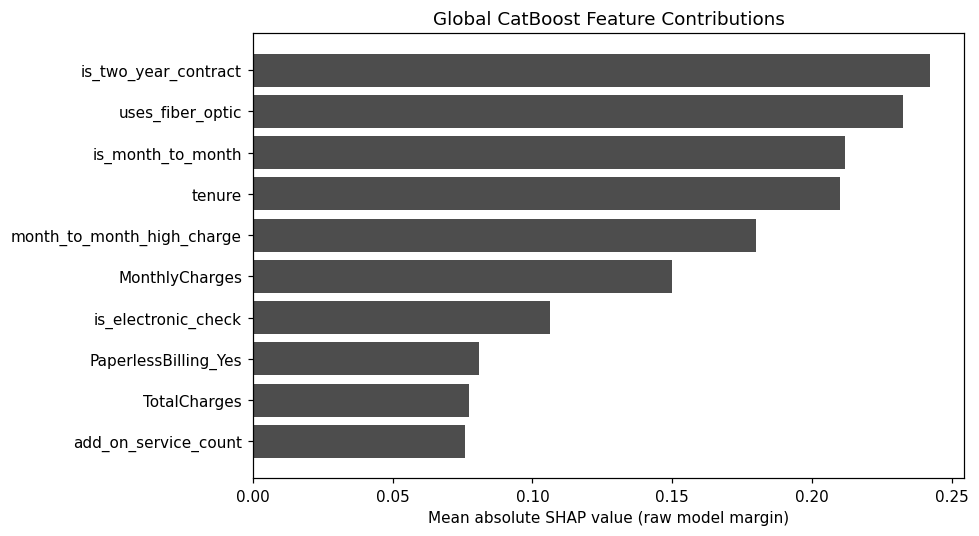

In [3]:
importance = pd.read_csv(OUT / "shap_global_importance.csv")
display(importance.head(10))
top = importance.head(10).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top["feature"], top["mean_abs_shap_value"], color="0.3")
plt.xlabel("Mean absolute SHAP value (raw model margin)")
plt.title("Global CatBoost Feature Contributions")
plt.tight_layout()
plt.show()

## Signed local SHAP explanations

These are SHAP contributions for the highest-scored customers, not LIME weights. Positive and negative contributions have different directions.

In [4]:
display(pd.read_csv(OUT / "shap_local_explanations.csv").head(15))

,customer_index,churn_probability,risk_level,feature,feature_value,shap_value
0,1360,0.876765,High Risk,month_to_month_high_charge,1.564411,0.249077
1,1360,0.876765,High Risk,is_month_to_month,0.904184,0.205158
2,1360,0.876765,High Risk,uses_fiber_optic,1.129102,0.201920
3,1360,0.876765,High Risk,tenure,-0.788800,0.175581
4,1360,0.876765,High Risk,is_two_year_contract,-0.562975,0.138236
5,5019,0.876253,High Risk,month_to_month_high_charge,1.564411,0.244363
6,5019,0.876253,High Risk,uses_fiber_optic,1.129102,0.200812
7,5019,0.876253,High Risk,is_month_to_month,0.904184,0.196879
8,5019,0.876253,High Risk,tenure,-0.748080,0.193565
9,5019,0.876253,High Risk,is_two_year_contract,-0.562975,0.133633


## LIME local explanations

LIME describes a local approximation in a sampled neighborhood. These rules are approximate and are not causal effects.

In [5]:
display(pd.read_csv(OUT / "lime_local_explanations.csv"))

,customer_index,churn_probability,risk_level,lime_feature_rule,lime_contribution
0,1360,0.876765,High Risk,is_two_year_contract <= -0.56,0.159743
1,1360,0.876765,High Risk,-0.89 < uses_fiber_optic <= 1.13,0.101009
2,1360,0.876765,High Risk,-0.64 < month_to_month_high_charge <= 1.56,0.094972
3,1360,0.876765,High Risk,MonthlyCharges > 0.83,0.052375
4,1360,0.876765,High Risk,-0.71 < is_electronic_check <= 1.41,0.047198
5,5019,0.876253,High Risk,is_two_year_contract <= -0.56,0.154689
6,5019,0.876253,High Risk,-0.89 < uses_fiber_optic <= 1.13,0.102885
7,5019,0.876253,High Risk,-0.64 < month_to_month_high_charge <= 1.56,0.092209
8,5019,0.876253,High Risk,MonthlyCharges > 0.83,0.058019
9,5019,0.876253,High Risk,-0.71 < is_electronic_check <= 1.41,0.054959


## Risk levels and scorecard

Low Risk is below 0.35, Medium Risk lies below the model threshold, and High Risk begins at that threshold. The top_risk_driver fields store the largest absolute SHAP contributions; a listed feature can also reduce a prediction.

,risk_level,n_customers,avg_churn_probability,actual_churn_rate
0,High Risk,2043,0.768947,0.556535
1,Low Risk,2968,0.171949,0.072439
2,Medium Risk,2032,0.481092,0.254429


,customer_index,churn_probability,risk_level,actual_churn,predicted_churn,top_risk_driver_1,top_risk_driver_2,top_risk_driver_3
0,0,0.537502,Medium Risk,0,0,uses_fiber_optic,is_month_to_month,tenure
1,1,0.280677,Low Risk,0,0,uses_fiber_optic,is_month_to_month,tenure
2,2,0.407558,Medium Risk,1,0,uses_fiber_optic,tenure,is_month_to_month
3,3,0.310781,Low Risk,0,0,uses_fiber_optic,is_month_to_month,is_two_year_contract
4,4,0.786143,High Risk,1,1,month_to_month_high_charge,uses_fiber_optic,is_month_to_month


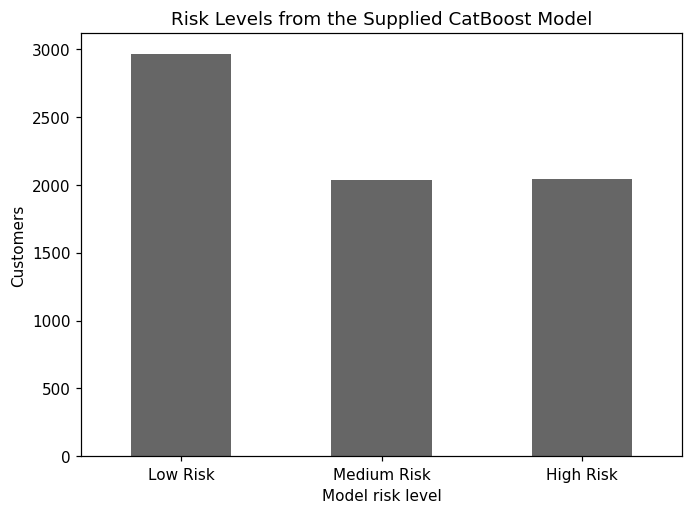

In [6]:
scorecard = pd.read_csv(scorecard_path)
summary = pd.read_csv(OUT / "risk_level_summary.csv")
display(summary)
display(scorecard.head())
summary.set_index("risk_level")["n_customers"].reindex(["Low Risk", "Medium Risk", "High Risk"]).plot(kind="bar", color="0.4")
plt.ylabel("Customers")
plt.xlabel("Model risk level")
plt.title("Risk Levels from the Supplied CatBoost Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Full-sample diagnostics

These metrics use the entire customer dataset, including training observations. They are not validation or test scores and should not replace the Week 6 evaluation.

In [7]:
display(pd.read_csv(OUT / "full_sample_diagnostic_metrics.csv"))

,scope,threshold,accuracy,precision,recall,f1_score,roc_auc,tn,fp,fn,tp
0,All customers; includes training observations,0.64,0.767429,0.556535,0.608347,0.581288,0.80864,4268,906,732,1137
